# Predictive Detection of Network Intrusions Using Machine Learning
### UNSW-NB15 Dataset | Network Intrusion Detection System (NIDS)

**Objective:** Build and compare machine-learning classifiers that classify network connections as Normal or as one of nine attack categories: Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode or Worms.

**Workflow:** Data understanding → preprocessing → model training → evaluation → interpretation.

> **Dataset setup:** Download `UNSW_NB15_training-set.csv` (175,341 records) and `UNSW_NB15_testing-set.csv` (82,332 records) from the official UNSW page (https://research.unsw.edu.au/projects/unsw-nb15-dataset) or a Kaggle mirror. Place both files in the same folder as this notebook. If your files have different names, update the paths in the load cell.
>
> **Runtime note:** the SVM is by far the slowest model on a training set this large. To keep the run practical, the SVM is trained on a stratified random sample of 60,000 training records (`SVM_TRAIN_LIMIT` in Section 7); set it to `None` to train on all 175,341 records, which can take an hour or more. Random Forest and XGBoost always use the full training set.

## 1. Import libraries and Setup Environment

Before writing any machine learning code, we import the Python libraries for handling data, plotting and modelling:
* **`numpy` & `pandas`**: store and manipulate the data as tables (DataFrames) and do fast array maths.
* **`matplotlib` & `seaborn`**: draw plots and charts.
* **`sklearn` (Scikit-Learn)**: preprocessing tools (scaling, one-hot encoding), the Random Forest and SVM models, and the evaluation metrics.
* **`xgboost`** (optional): the gradient-boosting model. If it is not installed the notebook still runs Random Forest and SVM.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid", palette="viridis")
RANDOM_STATE = 42

## 2. Load the UNSW-NB15 dataset

The **UNSW-NB15 dataset** was created at the Australian Centre for Cyber Security (UNSW Canberra) with the IXIA PerfectStorm tool. It mixes realistic modern normal traffic with synthetic contemporary attacks. The authors supply a ready-made **training file and testing file**, which we keep separate so that the test is honest.

Each row is one network flow described by 42 features (duration, protocol, service, state, packet and byte counts, rates, TTL values, connection counters and so on). Each row also contains:
1. **`attack_cat`**: the attack category (or `Normal`). This is our prediction target.
2. **`label`**: a 0/1 flag (0 = normal, 1 = attack). It is just a simplified copy of `attack_cat`, so we must **not** use it as an input.
3. **`id`**: a row number with no meaning for prediction.

In [2]:
# Change these paths if your downloaded files are stored elsewhere
TRAIN_PATH = "UNSW_NB15_training-set.csv"
TEST_PATH = "UNSW_NB15_testing-set.csv"

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
display(train_df.head())

Training shape: (175341, 45)
Testing shape: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


## 3. Data Understanding & Exploratory Analysis

We inspect the data before modelling:
* **`info()`**: number of entries, the data type of each column and whether any cells are empty.
* **Missing values**: most algorithms fail when values are missing.
* **Duplicate rows**: repeated rows can inflate or distort scores. We ignore the `id` column because it makes every row look unique.
* **Attack categories**: how many records belong to each category.

In [3]:
print("Training data information:")
train_df.info()
print("\nMissing values (train, test):", train_df.isnull().sum().sum(), test_df.isnull().sum().sum())
print("Duplicate rows in training data (ignoring id):", train_df.drop(columns=["id"]).duplicated().sum())
print("\nNumber of unique attack categories:", train_df["attack_cat"].nunique())
print(train_df["attack_cat"].value_counts())

Training data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              17534

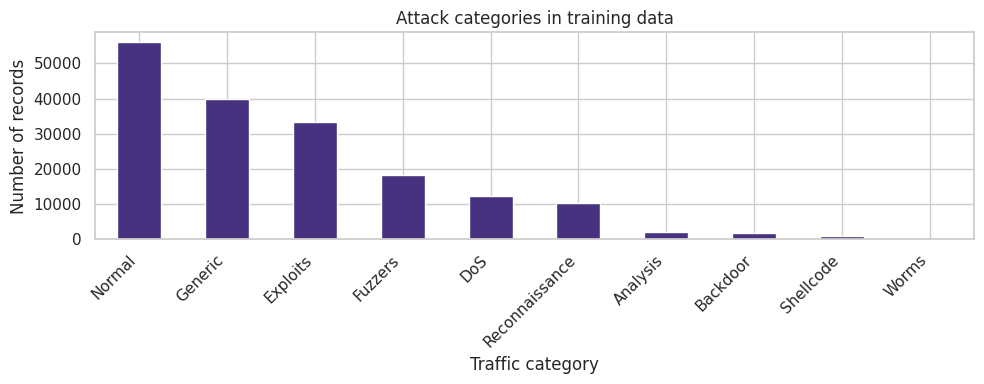

In [4]:
plt.figure(figsize=(10, 4))
train_df["attack_cat"].value_counts().plot(kind="bar")
plt.title("Attack categories in training data")
plt.xlabel("Traffic category")
plt.ylabel("Number of records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4. Defining the Prediction Target

In NSL-KDD we had to group dozens of attack names into families. UNSW-NB15 already provides **nine attack categories** plus `Normal`, so no manual grouping dictionary is needed. We only clean stray spaces from the category names and check that the training and testing files use the same categories:

1. **Generic**: attacks that work against any block cipher or hash, regardless of its structure.
2. **Exploits**: attacks that take advantage of a known software vulnerability.
3. **Fuzzers**: attacks that feed random or malformed data to try to crash a service.
4. **DoS**: Denial of Service attacks that exhaust a server's resources.
5. **Reconnaissance**: scanning and information gathering.
6. **Analysis**: port scans, spam and web-script probing.
7. **Backdoor**: techniques to bypass normal authentication and keep hidden access.
8. **Shellcode**: small pieces of code used to gain control of a machine after an exploit.
9. **Worms**: self-replicating malware that spreads across a network.

In [5]:
CLASSES = ["Normal", "Generic", "Exploits", "Fuzzers", "DoS",
           "Reconnaissance", "Analysis", "Backdoor", "Shellcode", "Worms"]

train_df["target"] = train_df["attack_cat"].astype(str).str.strip()
test_df["target"] = test_df["attack_cat"].astype(str).str.strip()

print("Training classes:", sorted(train_df["target"].unique()))
print("Categories only in test file:", sorted(set(test_df["target"]) - set(train_df["target"])))
print("Categories not in expected list:", sorted(set(train_df["target"]) - set(CLASSES)))
print("\nTraining counts:")
print(train_df["target"].value_counts().reindex(CLASSES))
print("\nTesting counts:")
print(test_df["target"].value_counts().reindex(CLASSES))

# Sanity check: the 0/1 label should simply say "not Normal"
print("\nlabel vs target (training):")
display(pd.crosstab(train_df["label"], train_df["target"] == "Normal"))

Training classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Categories only in test file: []
Categories not in expected list: []

Training counts:
target
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Testing counts:
target
Normal            37000
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64

label vs target (training):


target,False,True
label,,
0,0,56000
1,119341,0


### Preparing Features and Targets for Machine Learning

* **`X` (Features)**: the 42 network characteristics. We drop `id` (a row number), `label` (a 0/1 copy of the answer, which would leak the target), `attack_cat` (the original text) and `target` (the class we want to predict).
* **`y` (Target)**: the `target` column with the 10 categories.

In [6]:
X_train = train_df.drop(columns=["id", "label", "attack_cat", "target"])
y_train = train_df["target"]
X_test = test_df.drop(columns=["id", "label", "attack_cat", "target"])
y_test = test_df["target"]

print("Classes:", sorted(y_train.unique()))
print("Train:", X_train.shape, " Test:", X_test.shape)

Classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Train: (175341, 42)  Test: (82332, 42)


## 5. Feature Preprocessing Pipeline

Machine learning algorithms need numbers. Our dataset has three categorical (text) features: `proto` (protocol, e.g. tcp, udp), `service` (e.g. http, dns) and `state` (the connection state, e.g. FIN, CON).

The **Preprocessing Pipeline** does two things:
1. **One-Hot Encoding**: converts each text column into several 0/1 columns, one per category value. Categories that appear only in the test file are ignored instead of causing an error (`handle_unknown="ignore"`). This matters here because the test file contains some `state` values that never occur in training.
2. **Standard Scaling**: numeric values vary hugely (byte counts can be millions, rates are small). We scale each numeric column to mean 0 and variance 1 so that scale-sensitive models such as the SVM work properly.

Both steps are packaged in a `ColumnTransformer`, which is fitted on the training data only and then applied to the test data.

In [7]:
categorical_cols = ["proto", "service", "state"]
numeric_cols = [c for c in X_train.columns if c not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numeric_cols)
    ]
)

print("Categorical columns:", categorical_cols)
print("Numeric columns:", len(numeric_cols))
print("Levels in training:", {c: X_train[c].nunique() for c in categorical_cols})
print("Test levels never seen in training:", {c: sorted(set(X_test[c]) - set(X_train[c])) for c in categorical_cols})

Categorical columns: ['proto', 'service', 'state']
Numeric columns: 39
Levels in training: {'proto': 133, 'service': 13, 'state': 9}
Test levels never seen in training: {'proto': [], 'service': [], 'state': ['ACC', 'CLO']}


## 6. Managing Class Imbalance

Normal, Generic and Exploits dominate the training data, while Worms, Shellcode, Backdoor and Analysis are rare. A model trained on the raw data could ignore the rare attacks and still score decent accuracy.

We therefore compute **class-balanced sample weights**: each class gets the weight `n / (number of classes × class count)`, so mistakes on rare classes are penalised more during training.

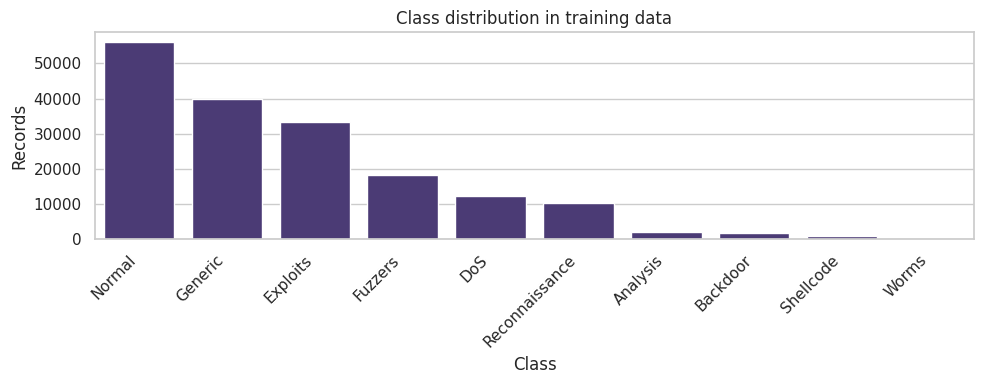

Class weights used for training:
Normal              0.313
Generic             0.438
Exploits            0.525
Fuzzers             0.964
DoS                 1.430
Reconnaissance      1.671
Analysis            8.767
Backdoor           10.042
Shellcode          15.476
Worms             134.878
dtype: float64


In [8]:
plt.figure(figsize=(10, 4))
sns.countplot(data=train_df, x="target", order=CLASSES)
plt.title("Class distribution in training data")
plt.xlabel("Class")
plt.ylabel("Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
weights_by_class = pd.Series(sample_weights, index=y_train.values).groupby(level=0).first().reindex(CLASSES)
print("Class weights used for training:")
print(weights_by_class.round(3))

## 7. Model Definitions

We use the same three algorithms as in the NSL-KDD notebook so the results can be compared:
1. **Random Forest**: builds many independent decision trees and combines their votes, giving a stable prediction.
2. **Support Vector Machine (SVM)**: finds the boundary that best separates the classes in a high-dimensional space (here with an RBF kernel). Because it is slow on large data, it is trained on a 60,000-record stratified sample.
3. **XGBoost**: trains trees one after another, each new tree correcting the errors of the previous ones.

In [9]:
# The SVM becomes very slow on 175,341 records, so it is trained on a stratified
# random sample of this size (set to None to use the full training set).
SVM_TRAIN_LIMIT = 60000

models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=150, random_state=RANDOM_STATE,
        class_weight="balanced_subsample", n_jobs=-1
    ),
    "SVM": SVC(
        kernel="rbf", C=1.0, class_weight="balanced"
    )
}

# Optional XGBoost
try:
    from xgboost import XGBClassifier
    label_encoder = LabelEncoder()
    y_train_encoded = label_encoder.fit_transform(y_train)
    xgb_model = XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=RANDOM_STATE, n_jobs=-1
    )
    models["XGBoost"] = xgb_model
    print("XGBoost is available.")
except ImportError:
    print("XGBoost not installed; Random Forest and SVM will run.")

XGBoost is available.


In [ ]:
trained_models = {}
predictions = {}
results = []
fit_seconds = {}

for name, model in models.items():
    print("Training:", name)
    t0 = time.time()
    if name == "XGBoost":
        Xtr = preprocessor.fit_transform(X_train)
        Xte = preprocessor.transform(X_test)
        model.fit(Xtr, y_train_encoded, sample_weight=sample_weights)
        pred_encoded = model.predict(Xte)
        pred = label_encoder.inverse_transform(pred_encoded.astype(int))
    else:
        X_fit, y_fit = X_train, y_train
        if name == "SVM" and SVM_TRAIN_LIMIT and len(X_train) > SVM_TRAIN_LIMIT:
            X_fit, _, y_fit, _ = train_test_split(
                X_train, y_train, train_size=SVM_TRAIN_LIMIT,
                stratify=y_train, random_state=RANDOM_STATE)
            print(f"   SVM trained on a stratified sample of {len(X_fit):,} records")
        pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
        pipe.fit(X_fit, y_fit)
        pred = pipe.predict(X_test)
        model = pipe
    fit_seconds[name] = round(time.time() - t0, 1)
    print(f"   done in {fit_seconds[name]} seconds")

    trained_models[name] = model
    predictions[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score (macro)", ascending=False)
display(results_df.round(4))

Training: Random Forest
   done in 1293.6 seconds
Training: SVM
   SVM trained on a stratified sample of 60,000 records


## 8. Detailed Evaluation Metrics

With imbalanced data, **accuracy** alone is misleading, so we also use:
* **Precision**: of all flows the model predicted as a category, how many really were that category?
* **Recall**: of all real flows of a category, how many did the model catch?
* **F1-Score**: the harmonic mean of precision and recall.
* **Macro averaging**: the metric is computed for each of the 10 classes and averaged without weighting, so rare classes such as Worms count as much as Normal.

In [ ]:
for name, pred in predictions.items():
    print("\n", "=" * 60)
    print(name)
    print(classification_report(y_test, pred, labels=CLASSES, zero_division=0))

## 9. Analyzing Confusion Matrices

Each row is an actual class and each column a predicted class. The diagonal shows correct predictions; off-diagonal numbers show which categories get confused with each other.

In [ ]:
for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=CLASSES)
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", annot_kws={"size": 8},
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Security view: missed attacks and false alarms

Two errors matter most to a security team:
* **Attack miss rate**: the share of real attacks predicted as `Normal` (a missed attack).
* **False-alarm rate**: the share of `Normal` flows predicted as an attack.

In [ ]:
rows = []
attack_mask = (y_test != "Normal").values
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Attacks missed (predicted Normal)": (pred[attack_mask] == "Normal").mean(),
        "False-alarm rate": (pred[~attack_mask] != "Normal").mean()
    })
security_df = pd.DataFrame(rows)
display(security_df.round(4))

## 10. Performance Comparison Visualizations

The accuracy, macro precision, macro recall and macro F1-score of all models are placed in one bar chart for an easy comparison.

In [ ]:
metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
plot_df = results_df.set_index("Model")[metrics]
ax = plot_df.plot(kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0)
ax.set_title("Performance comparison of intrusion detection models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 11. Explaining the Model: Feature Importance

For the Random Forest we can read **feature importances**, which show how much each feature helped reduce uncertainty when separating the classes. We plot the top 15 to see which flow characteristics (for example TTL values, byte counts or connection counters) are the strongest indicators of malicious traffic.

In [ ]:
if "Random Forest" in trained_models:
    rf_pipe = trained_models["Random Forest"]
    prep = rf_pipe.named_steps["preprocess"]
    rf = rf_pipe.named_steps["model"]

    feature_names = prep.get_feature_names_out()
    importances = rf.feature_importances_
    importance_all = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)
    importance_df = importance_all.head(15)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title("Top 15 Random Forest feature importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
    display(importance_df)
    print("Total importance of the top 15 features:", round(importance_df["Importance"].sum(), 3))

## 12. Real-Time Prediction Demonstration

To show how the system would work on live traffic, we take one flow from the test set, pass its raw features to the trained Random Forest pipeline and read the predicted category.

In [ ]:
if "Random Forest" in trained_models:
    sample = X_test.iloc[[0]]
    actual = y_test.iloc[0]
    predicted = trained_models["Random Forest"].predict(sample)[0]
    print("Actual class:", actual)
    print("Predicted class:", predicted)

## 13. Conclusion

This notebook implements a ten-class network intrusion detection workflow on the UNSW-NB15 dataset. It preprocesses the flow features (155 one-hot columns + 39 scaled numeric columns = 194 inputs), trains Random Forest, SVM and XGBoost with class-balanced weights, and evaluates them on the official test file of 82,332 flows with accuracy, macro precision, macro recall, macro F1-score, classification reports and confusion matrices.

**Measured results (official test file):**

| Model | Accuracy | Macro precision | Macro recall | Macro F1 |
|---|---|---|---|---|
| XGBoost | 0.6757 | 0.5164 | 0.6565 | 0.5006 |
| Random Forest | 0.7493 | 0.5316 | 0.5134 | 0.4832 |
| SVM (60,000-record sample) | 0.6354 | 0.4149 | 0.5546 | 0.3811 |

XGBoost has the best macro F1 and macro recall, while Random Forest has the best accuracy and macro precision, so the "best" model depends on the measure used. The macro F1-score is used as the main measure because it gives every class equal weight.

**Which categories were detected?** Generic (F1 about 0.98) and Reconnaissance (F1 0.56 to 0.86) were detected well. Analysis (F1 at most 0.08), Backdoor (at most 0.11) and DoS (0.23 to 0.24) were detected poorly. Backdoor is often predicted for DoS and Exploits flows, which gives it a very low precision (about 0.06).

**Errors that matter for security.** Very few attacks were predicted as Normal (0.2% to 2.8%), but many Normal flows were flagged as attacks (false-alarm rate 23% to 42%). For XGBoost, 11,887 of the 37,000 Normal test flows were predicted as Fuzzers. The first test flow used in Section 12 shows the same problem: it is Normal but is predicted as Fuzzers by the Random Forest.

**Top features.** The Random Forest relied most on `sbytes`, `smean`, `ct_dst_src_ltm`, `ct_srv_dst` and `sload`; the top 15 features carry about 60% of the total importance.

**Limitations:** UNSW-NB15 is a benchmark dataset and may not represent current real-world traffic. The SVM was trained on a 60,000-record sample for speed, no hyper-parameters were tuned, the results come from a single run, and 67,601 duplicate training rows were kept. A possible reason for the many false alarms is that the class mix differs between the training and testing files (Normal is 31.9% of training but 44.9% of testing), but this was not tested here. High test performance does not by itself establish readiness for deployment; a production NIDS would require validation on contemporary traffic, monitoring for data drift and careful false-positive analysis.

## 14. Save Results (optional)

This cell stores the measured results in `unsw_results.json`, so they can be reused in a report.

In [ ]:
def group_of(feature):
    base = feature.split("__", 1)[1]
    for c in categorical_cols:
        if base.startswith(c + "_"):
            return c
    return base

group_importance = importance_all.assign(Group=importance_all["Feature"].map(group_of)) \
                                 .groupby("Group")["Importance"].sum().sort_values(ascending=False)

out = {
    "classes": CLASSES,
    "fit_seconds": fit_seconds,
    "results": results_df.to_dict("records"),
    "weighted_f1": {n: float(f1_score(y_test, p, average="weighted", zero_division=0)) for n, p in predictions.items()},
    "report": {n: classification_report(y_test, p, labels=CLASSES, output_dict=True, zero_division=0) for n, p in predictions.items()},
    "cm": {n: confusion_matrix(y_test, p, labels=CLASSES).tolist() for n, p in predictions.items()},
    "security": security_df.to_dict("records"),
    "importance_top15": importance_df.to_dict("records"),
    "importance_groups": group_importance.head(10).to_dict(),
    "n_inputs": int(len(feature_names)),
    "train_counts": y_train.value_counts().reindex(CLASSES).to_dict(),
    "test_counts": y_test.value_counts().reindex(CLASSES).to_dict(),
    "class_weights": weights_by_class.to_dict(),
    "duplicates_train": int(train_df.drop(columns=["id"]).duplicated().sum()),
    "levels": {c: int(X_train[c].nunique()) for c in categorical_cols},
    "unseen_test_levels": {c: sorted(set(X_test[c]) - set(X_train[c])) for c in categorical_cols},
    "n_numeric": len(numeric_cols),
    "svm_train_limit": SVM_TRAIN_LIMIT,
    "sample": {"actual": str(y_test.iloc[0]), "predicted": str(trained_models["Random Forest"].predict(X_test.iloc[[0]])[0])},
}
with open("unsw_results.json", "w") as f:
    json.dump(out, f, indent=1, default=float)
print("Saved unsw_results.json")